# 03 · Del dato a la decisión — modelado, pronóstico y factibilidad

**Trabajo final integrador de Analítica para Negocios** sobre el Observatorio de la Economía del Cuidado (PP7, UNRC).

Los notebooks 01 y 02 dejaron el **diagnóstico descriptivo**: dónde y cuánto cuidan las mujeres de la CDMX y dónde no tienen respaldo cercano. Este notebook agrega las tres capas que faltaban y termina en una decisión:

| Sección | Tipo de analítica | Pregunta | Fuente |
|---|---|---|---|
| 1. Serie de la oferta | Descriptiva y diagnóstica | ¿La oferta formal de respaldo crece o se contrae? | DENUE, 19 ediciones (01/2016 a 05/2026) |
| 2. Pronóstico de la oferta | Predictiva | ¿Qué oferta habrá en los próximos 1 y 3 semestres? | DENUE |
| 3. Modelo de horas de cuidado | Predictiva | ¿Cuántas horas cuida una mujer según la composición de su hogar? | ENUT 2024 (microdatos) |
| 4. Horas de cuidado por AGEB | Predictiva (áreas pequeñas) | ¿Cuántas horas de cuidado no remunerado se hacen en cada AGEB? | Modelo + Censo 2020 |
| 5. Factibilidad del programa | Prescriptiva | ¿Conviene invertir en una red de cuidado a domicilio en Iztapalapa? ¿Bajo qué condiciones? | Modelo financiero (`backend/observatorio/factibilidad.py`) |

Al final, la sección 6 exporta las tablas a `data/curada/` (las carga el ETL a `indicadores`) y genera el anexo de Excel con fórmulas.

> **Escenario simulado.** El programa y su operador (Centro Comunitario «Manos que Cuidan», Iztapalapa) son hipotéticos: así lo decidió el equipo al no tener institución de partida. Los datos del observatorio son reales y públicos.

In [1]:
from pathlib import Path
import io, sys, math, shutil, urllib.request, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore')   # avisos de convergencia de statsmodels en series cortas
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, CUR, FIG = BASE / 'data' / 'raw', BASE / 'data' / 'curada', BASE / 'figuras'
ANEXOS = BASE / 'docs' / 'anexos'
for p in (RAW, CUR, FIG, ANEXOS):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(BASE / 'backend'))
sys.path.insert(0, str(BASE / 'notebooks'))
from observatorio import factibilidad as fac

SEMILLA = 7
MORADO, GRIS, ROJO = '#6f5bf0', '#898781', '#d03b3b'

# Mismas fuentes y descarga idempotente que los notebooks 01 y 02.
FUENTES = {
    'denue_09': 'https://www.inegi.org.mx/contenidos/masiva/denue/denue_09_csv.zip',
    'censo_ageb_09': 'https://www.inegi.org.mx/contenidos/programas/ccpv/2020/datosabiertos/ageb_manzana/ageb_mza_urbana_09_cpv2020_csv.zip',
    'enut_2024': 'https://www.inegi.org.mx/contenidos/programas/enut/2024/datosabiertos/conjunto_de_datos_enut_2024_csv.zip',
}

def descargar(nombre, url):
    zpath, dpath = RAW / f'{nombre}.zip', RAW / nombre
    if not zpath.exists():
        print(f'Descargando {nombre}...')
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as r, open(zpath, 'wb') as f:
            shutil.copyfileobj(r, f)
    if not dpath.exists():
        with zipfile.ZipFile(zpath) as z:
            z.extractall(dpath)
    return dpath

DIRS = {k: descargar(k, u) for k, u in FUENTES.items()}

---
## 1. La oferta formal de respaldo, 2016–2026 (DENUE)

El DENUE se publica dos veces al año y el INEGI conserva las ediciones anteriores. Contamos, en cada edición, los mismos establecimientos de **respaldo** que usa el observatorio (mismas claves SCIAN del notebook 02): guarderías (`624411/2`), residencias y asilos para personas mayores (`623311/2`) y centros de día (`624121/2`).

Para no guardar ~20 GB, cada edición se descarga, se cuenta y se borra; solo queda el conteo en `data/raw/denue_historico/conteos.csv` (fuera de git, como el resto de `data/raw/`). Las ediciones de 05/2023 y 11/2025 no están publicadas con el mismo nombre de archivo y faltan en la serie.

In [2]:
EDICIONES = ['2016_01', '2016_10', '2017_03', '2017_11', '2018_03', '2018_11', '2019_04', '2019_11',
             '2020_04', '2020_11', '2021_05', '2021_11', '2022_05', '2022_11', '2023_11', '2024_05',
             '2024_11', '2025_05']                         # la de 05/2026 es la actual (data/raw/denue_09)
RESPALDO = {'624411': ('Guardería', 'Privado'), '624412': ('Guardería', 'Público'),
            '623311': ('Residencia / asilo', 'Privado'), '623312': ('Residencia / asilo', 'Público'),
            '624121': ('Centro de día', 'Privado'), '624122': ('Centro de día', 'Público')}
HIST = RAW / 'denue_historico'; HIST.mkdir(exist_ok=True)
CONTEOS = HIST / 'conteos.csv'

def contar_respaldo(abrir_csv):
    """Lee solo la columna del código SCIAN y cuenta los establecimientos de respaldo."""
    encabezado = pd.read_csv(abrir_csv(), nrows=0, encoding='latin-1').columns
    col = next(c for c in encabezado if 'codigo_act' in c.lower())
    codigos = pd.read_csv(abrir_csv(), usecols=[col], dtype=str, encoding='latin-1')[col].str.strip()
    return codigos[codigos.isin(RESPALDO)].value_counts()

def conteo_edicion(edicion):
    if edicion == '2026_05':
        rutas = sorted(DIRS['denue_09'].rglob('conjunto_de_datos/*.csv'))
        return sum((contar_respaldo(lambda p=p: open(p, 'rb')) for p in rutas), pd.Series(dtype=int))
    anio, mes = edicion.split('_')
    url = f'https://www.inegi.org.mx/contenidos/masiva/denue/{edicion}/denue_09_{mes}{anio[2:]}_csv.zip'
    zpath = HIST / f'{edicion}.zip'
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=600) as r, open(zpath, 'wb') as f:
        shutil.copyfileobj(r, f)
    try:
        with zipfile.ZipFile(zpath) as z:
            nombres = [n for n in z.namelist() if n.lower().endswith('.csv')
                       and n.split('/')[-1].lower().startswith('denue_inegi')]
            return sum((contar_respaldo(lambda n=n: io.BytesIO(z.read(n))) for n in nombres), pd.Series(dtype=int))
    finally:
        zpath.unlink()

previos = pd.read_csv(CONTEOS, dtype={'codigo_act': str}) if CONTEOS.exists() else pd.DataFrame(columns=['edicion', 'codigo_act', 'n'])
for ed in EDICIONES + ['2026_05']:
    if ed in set(previos['edicion']):
        continue
    print('Contando', ed)
    s = conteo_edicion(ed)
    previos = pd.concat([previos, pd.DataFrame({'edicion': ed, 'codigo_act': s.index, 'n': s.values})])
    previos.to_csv(CONTEOS, index=False)

conteos = previos.copy()
conteos['n'] = conteos['n'].astype(int)
conteos[['tipo', 'sector']] = conteos['codigo_act'].map(RESPALDO).apply(pd.Series)
oferta = (conteos.groupby(['edicion', 'tipo', 'sector'])['n'].sum()
          .unstack(['tipo', 'sector'], fill_value=0).stack(['tipo', 'sector'], future_stack=True)
          .rename('establecimientos').reset_index())
oferta['periodo'] = oferta['edicion'].map(lambda e: f"{e[:4]}-S{1 if int(e[5:]) <= 6 else 2}")
oferta['edicion'] = oferta['edicion'].str.replace('_', '-')
tabla = oferta.pivot_table(index='edicion', columns='tipo', values='establecimientos', aggfunc='sum')
tabla['Total de respaldo'] = tabla.sum(axis=1)
tabla

tipo,Centro de día,Guardería,Residencia / asilo,Total de respaldo
edicion,,,,
2016-01,109,1144,84,1337
2016-10,109,1146,84,1339
2017-03,108,1145,84,1337
2017-11,107,1152,87,1346
2018-03,107,1152,87,1346
2018-11,107,1152,87,1346
2019-04,107,1152,84,1343
2019-11,112,936,102,1150
2020-04,124,761,105,990


In [3]:
total = tabla['Total de respaldo']
assert total.loc['2026-05'] == 838, 'la edición actual debe cuadrar con indicadores.establecimientos_cuidado (838)'
cambio = (total.loc['2026-05'] / total.loc['2016-01'] - 1) * 100
g = tabla['Guardería']
print(f"Respaldo total: {total.loc['2016-01']:,} (01/2016) → {total.loc['2026-05']:,} (05/2026): {cambio:+.1f} %")
print(f"Guarderías:     {g.loc['2016-01']:,} → {g.loc['2026-05']:,}: {(g.loc['2026-05'] / g.loc['2016-01'] - 1) * 100:+.1f} %")
for tipo in ['Residencia / asilo', 'Centro de día']:
    print(f"{tipo:15} {tabla[tipo].loc['2016-01']:,} → {tabla[tipo].loc['2026-05']:,}")
pub = oferta[oferta.tipo == 'Guardería'].pivot_table(index='edicion', columns='sector', values='establecimientos')
print('\nGuarderías por sector:'); print(pub.loc[['2016-01', '2019-04', '2019-11', '2020-04', '2024-05', '2024-11', '2026-05']].to_string())

Respaldo total: 1,337 (01/2016) → 838 (05/2026): -37.3 %
Guarderías:     1,144 → 603: -47.3 %
Residencia / asilo 84 → 109
Centro de día   109 → 126

Guarderías por sector:
sector   Privado  Público
edicion                  
2016-01    753.0    391.0
2019-04    761.0    391.0
2019-11    622.0    314.0
2020-04    465.0    296.0
2024-05    462.0    298.0
2024-11    329.0    263.0
2026-05    340.0    263.0


**Lectura.** La oferta de respaldo **no crece: se contrajo 37 %** en diez años, y casi todo por las guarderías (−47 %). La caída no es gradual, llega en dos escalones:

1. **2019-S2 a 2020-S1** (1,343 → 990). Coincide con la cancelación del Programa de Estancias Infantiles (febrero de 2019) y con la incorporación de los Censos Económicos 2019 al DENUE.
2. **2024-S2** (994 → 822). Coincide con la incorporación de los Censos Económicos 2024.

Entre escalones, la serie casi no se mueve. Eso dice algo del **método** y no solo de la realidad: el DENUE se actualiza a fondo cuando entra un censo económico, cada cinco años. Los cierres se acumulan y aparecen de golpe. Las residencias (+30 %) y los centros de día (+16 %) crecen, pero desde una base muy chica.

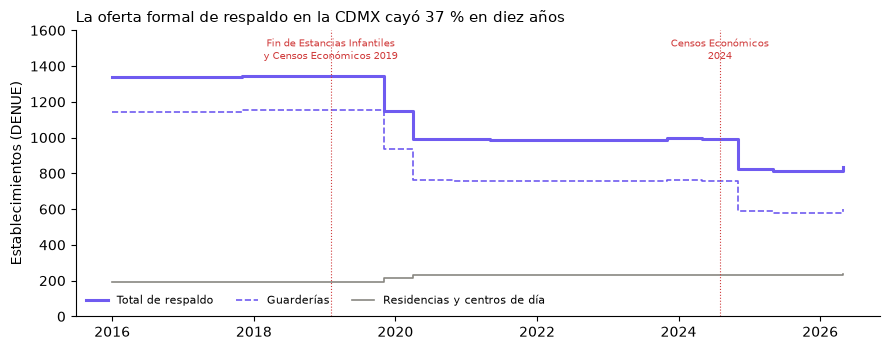

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = pd.to_datetime(tabla.index + '-01')
ax.step(x, tabla['Total de respaldo'], where='post', color=MORADO, lw=2.2, label='Total de respaldo')
ax.step(x, tabla['Guardería'], where='post', color=MORADO, lw=1.2, ls='--', label='Guarderías')
ax.step(x, tabla['Residencia / asilo'] + tabla['Centro de día'], where='post', color=GRIS, lw=1.2, label='Residencias y centros de día')
for fecha, texto in [('2019-02-01', 'Fin de Estancias Infantiles\ny Censos Económicos 2019'), ('2024-08-01', 'Censos Económicos\n2024')]:
    ax.axvline(pd.Timestamp(fecha), color=ROJO, lw=0.8, ls=':')
    ax.text(pd.Timestamp(fecha), 1420, texto, fontsize=7.5, color=ROJO, ha='center', va='bottom')
ax.set_ylim(0, 1600); ax.set_ylabel('Establecimientos (DENUE)')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower left')
ax.set_title('La oferta formal de respaldo en la CDMX cayó 37 % en diez años', loc='left', fontsize=11)
plt.tight_layout(); fig.savefig(FIG / 'oferta_respaldo_2016_2026.png', dpi=150, bbox_inches='tight'); plt.show()

---
## 2. Pronóstico de la oferta: próximos 1 y 3 semestres

**Serie.** Un valor por semestre (S1 = enero a junio, S2 = julio a diciembre), de 2016-S1 a 2026-S1: 21 periodos. Los dos semestres sin edición publicada (2023-S1 y 2025-S2) se llenan con el valor anterior. Es lo correcto para un directorio: si no hubo edición, el registro no cambió.

**Modelos comparados.** Ingenuo (último valor), deriva (tendencia lineal del primer al último punto), suavizamiento exponencial simple (SES), Holt con tendencia amortiguada y ARIMA(0,1,1).

**Validación.** Origen móvil. Cada modelo se entrena con los datos hasta un semestre y pronostica 1 y 3 semestres adelante, desde el semestre 12 hasta el final: 9 pronósticos a h = 1 y 7 a h = 3. Se mide MAPE, RMSE y MAE.

In [5]:
SEMESTRES = [f'{a}-S{s}' for a in range(2016, 2027) for s in (1, 2)][:21]
SERIES = ['Total de respaldo', 'Guardería', 'Residencia / asilo', 'Centro de día']
por_periodo = tabla.copy(); por_periodo.index = [f"{e[:4]}-S{1 if int(e[5:]) <= 6 else 2}" for e in tabla.index]
semestral = por_periodo.reindex(SEMESTRES).ffill()
print('Semestres llenados con el valor anterior:', [s for s in SEMESTRES if s not in por_periodo.index])

def f_ingenuo(y, H): return np.repeat(y[-1], H)
def f_deriva(y, H): return y[-1] + (y[-1] - y[0]) / (len(y) - 1) * np.arange(1, H + 1)
def f_ses(y, H): return ExponentialSmoothing(y, trend=None, initialization_method='estimated').fit().forecast(H)
def f_holt(y, H): return ExponentialSmoothing(y, trend='add', damped_trend=True, initialization_method='estimated').fit().forecast(H)
def f_arima(y, H): return ARIMA(y, order=(0, 1, 1)).fit().forecast(H)
METODOS = {'Ingenuo': f_ingenuo, 'Deriva': f_deriva, 'Suavizamiento simple': f_ses,
           'Holt amortiguado': f_holt, 'ARIMA(0,1,1)': f_arima}
ORIGEN_MIN = 12

def backtest(y, f, H):
    pares = [(y[o + H - 1], f(y[:o], H)[H - 1]) for o in range(ORIGEN_MIN, len(y) - H + 1)]
    real, pred = np.array(pares).T
    e = real - pred
    return {'MAPE': np.mean(np.abs(e / real)) * 100, 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAE': np.mean(np.abs(e)), 'n': len(e)}

y_total = semestral['Total de respaldo'].to_numpy(float)
bt = pd.DataFrame([{'h': H, 'modelo': m, **backtest(y_total, f, H)} for H in (1, 3) for m, f in METODOS.items()])
bt.round(2)

Semestres llenados con el valor anterior: ['2023-S1', '2025-S2']


,h,modelo,MAPE,RMSE,MAE,n
0,1,Ingenuo,2.92,58.11,24.33,9
1,1,Deriva,5.03,58.62,44.05,9
2,1,Suavizamiento simple,2.92,58.11,24.33,9
3,1,Holt amortiguado,4.94,59.15,43.20,9
4,1,"ARIMA(0,1,1)",5.52,72.36,46.04,9
5,3,Ingenuo,9.79,115.61,80.43,7
6,3,Deriva,11.48,101.77,101.19,7
7,3,Suavizamiento simple,9.79,115.61,80.43,7
8,3,Holt amortiguado,11.68,103.76,102.49,7
9,3,"ARIMA(0,1,1)",12.25,130.00,101.11,7


**Gana el modelo ingenuo** en los dos horizontes (MAPE de 2.9 % a un semestre y de 9.8 % a tres). Empata con el suavizamiento simple, que con esta serie estima un α ≈ 1 y se vuelve lo mismo. Los modelos con tendencia (deriva, Holt) arrastran los dos escalones como si fueran una pendiente y pronostican caídas que no ocurren entre censos. ARIMA reacciona tarde.

Es el resultado esperable en una serie que se mueve a saltos, y se elige el modelo más simple que gana: **«la oferta se queda donde está» es el mejor pronóstico estadístico**. Los modelos con tendencia sirven como escenario pesimista de la oferta.

**Intervalos.** Los errores no son normales: casi siempre son cero y, de vez en cuando, una caída grande. Por eso el intervalo es **empírico**, con los cuantiles de los cambios históricos a h semestres sumados al último valor. El resultado es asimétrico: la oferta puede quedarse igual o caer mucho, pero no tiene historia de subir.

In [6]:
PERIODOS_FUT = ['2026-S2', '2027-S1', '2027-S2']
filas_pron = []
for serie in SERIES:
    y = semestral[serie].to_numpy(float)
    for metodo, f in METODOS.items():
        p = f(y, 3)
        for h in (1, 2, 3):
            fila = {'serie': serie, 'metodo': metodo, 'periodo': PERIODOS_FUT[h - 1], 'horizonte': h,
                    'pronostico': float(p[h - 1]), 'li_80': None, 'ls_80': None, 'li_95': None, 'ls_95': None,
                    'elegido': metodo == 'Ingenuo'}
            if metodo == 'Ingenuo':
                cambios = y[h:] - y[:-h]
                fila.update({'li_80': y[-1] + np.quantile(cambios, 0.10), 'ls_80': y[-1] + np.quantile(cambios, 0.90),
                             'li_95': y[-1] + np.quantile(cambios, 0.025), 'ls_95': y[-1] + np.quantile(cambios, 0.975)})
            filas_pron.append(fila)
pronostico = pd.DataFrame(filas_pron)
pronostico[(pronostico.serie == 'Total de respaldo') & pronostico.horizonte.isin([1, 3])].round(1)

,serie,metodo,periodo,horizonte,pronostico,li_80,ls_80,li_95,ls_95,elegido
0,Total de respaldo,Ingenuo,2026-S2,1,838.0,676.8,847.1,655.0,855.9,True
2,Total de respaldo,Ingenuo,2027-S2,3,838.0,595.5,847.3,484.1,851.4,True
3,Total de respaldo,Deriva,2026-S2,1,813.0,NaN,NaN,NaN,NaN,False
5,Total de respaldo,Deriva,2027-S2,3,763.2,NaN,NaN,NaN,NaN,False
6,Total de respaldo,Suavizamiento simple,2026-S2,1,838.0,NaN,NaN,NaN,NaN,False
8,Total de respaldo,Suavizamiento simple,2027-S2,3,838.0,NaN,NaN,NaN,NaN,False
9,Total de respaldo,Holt amortiguado,2026-S2,1,814.3,NaN,NaN,NaN,NaN,False
11,Total de respaldo,Holt amortiguado,2027-S2,3,767.4,NaN,NaN,NaN,NaN,False
12,Total de respaldo,"ARIMA(0,1,1)",2026-S2,1,851.8,NaN,NaN,NaN,NaN,False
14,Total de respaldo,"ARIMA(0,1,1)",2027-S2,3,851.8,NaN,NaN,NaN,NaN,False


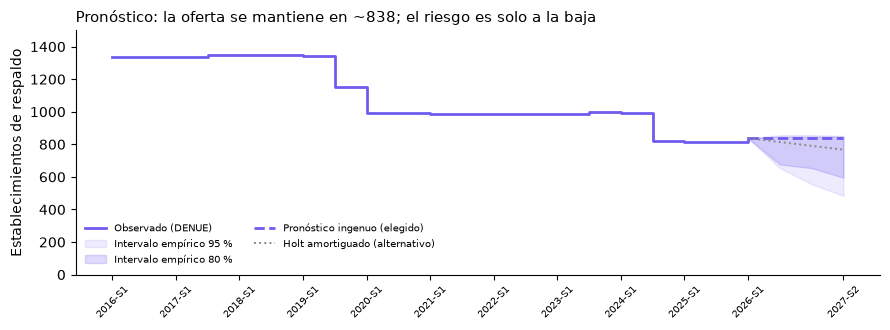

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.4))
xs = np.arange(len(SEMESTRES)); xf = np.arange(len(SEMESTRES) - 1, len(SEMESTRES) + 3)
ax.plot(xs, y_total, color=MORADO, lw=2, drawstyle='steps-post', label='Observado (DENUE)')
ing = pronostico[(pronostico.serie == 'Total de respaldo') & (pronostico.metodo == 'Ingenuo')]
holt = pronostico[(pronostico.serie == 'Total de respaldo') & (pronostico.metodo == 'Holt amortiguado')]
ax.fill_between(xf, [y_total[-1]] + list(ing.li_95), [y_total[-1]] + list(ing.ls_95), color=MORADO, alpha=.12, label='Intervalo empírico 95 %')
ax.fill_between(xf, [y_total[-1]] + list(ing.li_80), [y_total[-1]] + list(ing.ls_80), color=MORADO, alpha=.22, label='Intervalo empírico 80 %')
ax.plot(xf, [y_total[-1]] + list(ing.pronostico), color=MORADO, lw=2, ls='--', label='Pronóstico ingenuo (elegido)')
ax.plot(xf, [y_total[-1]] + list(holt.pronostico), color=GRIS, lw=1.4, ls=':', label='Holt amortiguado (alternativo)')
ax.set_xticks(list(xs[::2]) + [xf[-1]]); ax.set_xticklabels(SEMESTRES[::2] + [PERIODOS_FUT[-1]], rotation=45, fontsize=7.5)
ax.set_ylim(0, 1500); ax.set_ylabel('Establecimientos de respaldo')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, fontsize=7.5, loc='lower left', ncol=2)
ax.set_title('Pronóstico: la oferta se mantiene en ~838; el riesgo es solo a la baja', loc='left', fontsize=11)
plt.tight_layout(); fig.savefig(FIG / 'pronostico_oferta_respaldo.png', dpi=150, bbox_inches='tight'); plt.show()

> **Ojo con el horizonte.** El pronóstico no puede anticipar dos cosas que están fuera de la serie: (a) los **300 Centros de Cuidado Infantil** que anunció el Gobierno de la CDMX al instalar la Junta del Sistema de Cuidados (septiembre de 2026), que subirían la oferta de guarderías; y (b) los próximos **Censos Económicos (2029)**, que podrían traer otro escalón hacia abajo. Por eso la factibilidad trata la oferta como un riesgo de mercado y no como un dato.

---
## 3. Modelo predictivo: horas de cuidado de una mujer según su hogar (ENUT 2024)

**Objetivo del modelo.** Predecir las horas semanales de **cuidado no remunerado a integrantes del hogar** (`trab_no_rem_cuid_hog`, sin cuidados pasivos, el mismo indicador del observatorio) de cada mujer de 15 a 59 años. Es la población que usa el Censo en el denominador de la carga.

**Por qué este modelo.** El observatorio sabe *dónde* hay más personas que necesitan cuidado (Censo, por AGEB) y *cuánto* cuidan las mujeres (ENUT, solo por entidad), pero no tiene las dos cosas juntas. Un modelo que explique las horas con variables **que también existen en el Censo por AGEB** permite estimar las horas en cada AGEB. Es la *estimación en áreas pequeñas* que el equipo dejó pendiente.

**Variables independientes** (todas tienen su equivalente en el Censo 2020 por AGEB):

| Variable (ENUT, por mujer) | Equivalente en el Censo por AGEB |
|---|---|
| Niñas y niños de 0 a 5 en su hogar | (P_0A2 + P_3A5) / TOTHOG |
| Niñas y niños de 6 a 14 en su hogar | (P_6A11 + P_12A14) / TOTHOG |
| Personas de 60+ en su hogar | P_60YMAS / TOTHOG |
| Personas con discapacidad para bañarse, vestirse o comer en su hogar | PCDISC_MOT2 / TOTHOG |
| Tamaño del hogar | PROM_OCUP |
| Tiene de 15 a 24 años | (P_15A17_F + P_18A24_F) / mujeres de 15 a 59 |
| Tiene de 50 a 59 años | (mujeres de 15 a 59 − P_15A49_F) / mujeres de 15 a 59 |
| Está ocupada | POCUPADA_F / P_12YMAS_F |
| Años de escolaridad | GRAPROES_F |
| Vive en un hogar con jefatura femenina | PHOGJEF_F / POBHOG |
| Localidad de 100 mil habitantes o más | 1 (todas las AGEB urbanas de la CDMX) |

In [8]:
E = DIRS['enut_2024']
tv = pd.read_csv(next(E.rglob('*tvar_crea*/conjunto_de_datos/*.csv')), dtype=str, encoding='utf-8-sig')
sd = pd.read_csv(next(E.rglob('*tsdem*/conjunto_de_datos/*.csv')), dtype=str, encoding='utf-8-sig')
sd['edad'] = pd.to_numeric(sd['edad'], errors='coerce'); sd['fac_hog'] = pd.to_numeric(sd['fac_hog'])
sd['disc'] = sd['p3_6_6'].isin(['3', '4'])            # mucha dificultad o no puede: misma definición que el Censo
jefa = sd[sd['paren'] == '1'].set_index('llavehog')['sexo'].eq('2')
hog = sd.groupby('llavehog').agg(
    n_0a5=('edad', lambda e: int((e <= 5).sum())), n_6a14=('edad', lambda e: int(e.between(6, 14).sum())),
    n_60mas=('edad', lambda e: int((e >= 60).sum())), n_disc=('disc', 'sum'), tam=('edad', 'size'),
    fac_hog=('fac_hog', 'first'), cve_ent=('cve_ent', 'first'))
hog['jefa_hog'] = jefa.reindex(hog.index).fillna(False).astype(int)

for c in ['edad', 'fac_per', 'trab_no_rem_cuid_hog']:
    tv[c] = pd.to_numeric(tv[c], errors='coerce')
# Años de escolaridad a partir del nivel y el grado aprobados.
NIVEL_BASE = {'00': 0, '01': 0, '02': 0, '03': 6, '04': 9, '05': 9, '06': 9, '07': 12, '08': 12, '09': 16, '10': 16, '11': 18}
tv['anios_esc'] = (tv['niv'].map(NIVEL_BASE) + pd.to_numeric(tv['gra'], errors='coerce').fillna(0)).clip(upper=22)
tv.loc[tv['niv'].isin(['00', '01']), 'anios_esc'] = 0
tv['ocupada'] = (tv['cond_aee'] == '1').astype(int)
tv['urbana'] = (tv['tloc'] == '1').astype(int)

mujeres = tv[(tv['sexo'] == '2') & tv['edad'].between(15, 59)].join(hog.drop(columns=['cve_ent', 'fac_hog']), on='llavehog')
mujeres['edad_15a24'] = mujeres['edad'].between(15, 24).astype(int)
mujeres['edad_50a59'] = mujeres['edad'].between(50, 59).astype(int)
X_COLS = ['n_0a5', 'n_6a14', 'n_60mas', 'n_disc', 'tam', 'edad_15a24', 'edad_50a59', 'ocupada', 'anios_esc', 'jefa_hog', 'urbana']
Y = 'trab_no_rem_cuid_hog'
antes = len(mujeres)
mujeres = mujeres.dropna(subset=X_COLS + [Y, 'fac_per']).reset_index(drop=True)
print(f'Mujeres de 15 a 59 en la ENUT: {antes:,} · con datos completos: {len(mujeres):,} · CDMX: {(mujeres.cve_ent == "09").sum():,}')
print(f'Horas de cuidado a la semana (promedio ponderado, incluye a quien no cuida): nacional {np.average(mujeres[Y], weights=mujeres.fac_per):.2f} · '
      f'CDMX {np.average(mujeres.loc[mujeres.cve_ent == "09", Y], weights=mujeres.loc[mujeres.cve_ent == "09", "fac_per"]):.2f}')
mujeres[X_COLS + [Y]].describe().T[['mean', 'std', 'min', 'max']].round(2)

Mujeres de 15 a 59 en la ENUT: 30,302 · con datos completos: 30,301 · CDMX: 804
Horas de cuidado a la semana (promedio ponderado, incluye a quien no cuida): nacional 11.53 · CDMX 9.37


,mean,std,min,max
n_0a5,0.35,0.63,0.0,5.00
n_6a14,0.69,0.89,0.0,7.00
n_60mas,0.28,0.57,0.0,5.00
n_disc,0.03,0.17,0.0,2.00
tam,4.14,1.84,1.0,18.00
edad_15a24,0.25,0.43,0.0,1.00
edad_50a59,0.18,0.39,0.0,1.00
ocupada,0.57,0.50,0.0,1.00
anios_esc,10.41,4.14,0.0,22.00
jefa_hog,0.38,0.49,0.0,1.00


**Estrategia de entrenamiento.**

- **División 80/20 por hogar** (`GroupShuffleSplit`). Las mujeres de un mismo hogar comparten la composición del hogar; si unas quedaran en entrenamiento y otras en prueba, el modelo "vería" la respuesta.
- **Validación cruzada de 5 pliegues**, también agrupada por hogar, dentro del 80 % de entrenamiento.
- **Pesos.** El factor de expansión `fac_per`, para que el modelo represente a la población y no a la muestra.
- **Modelo seleccionado: regresión lineal múltiple. Alternativo: Random Forest** (300 árboles, mínimo 20 casos por hoja).

In [9]:
X, y, w, grupos = mujeres[X_COLS].to_numpy(float), mujeres[Y].to_numpy(float), mujeres['fac_per'].to_numpy(float), mujeres['llavehog'].to_numpy()
ent, prueba = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA).split(X, y, grupos))

def metricas(yt, yp, wt):
    return {'RMSE': float(np.sqrt(mean_squared_error(yt, yp, sample_weight=wt))),
            'MAE': float(mean_absolute_error(yt, yp, sample_weight=wt)), 'R2': float(r2_score(yt, yp, sample_weight=wt))}

def nuevo(nombre):
    return LinearRegression() if nombre == 'Regresión lineal' else RandomForestRegressor(
        n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEMILLA)

MODELOS = ['Regresión lineal', 'Random Forest']
res_ind, ajustados = [], {}
for nombre in MODELOS:
    m = nuevo(nombre).fit(X[ent], y[ent], sample_weight=w[ent]); ajustados[nombre] = m
    res_ind.append({'modelo': nombre, 'conjunto': 'Prueba (20 %)', **metricas(y[prueba], m.predict(X[prueba]), w[prueba])})
    cv = []
    for a, b in GroupKFold(n_splits=5).split(X[ent], y[ent], grupos[ent]):
        mm = nuevo(nombre).fit(X[ent][a], y[ent][a], sample_weight=w[ent][a])
        cv.append(metricas(y[ent][b], mm.predict(X[ent][b]), w[ent][b]))
    res_ind.append({'modelo': nombre, 'conjunto': 'Validación cruzada (5 pliegues)', **pd.DataFrame(cv).mean().to_dict()})
    res_ind.append({'modelo': nombre, 'conjunto': 'Validación cruzada, desv. estándar del RMSE', 'RMSE': pd.DataFrame(cv)['RMSE'].std()})
pd.DataFrame(res_ind).round(3)

,modelo,conjunto,RMSE,MAE,R2
0,Regresión lineal,Prueba (20 %),12.560,8.272,0.311
1,Regresión lineal,Validación cruzada (5 pliegues),13.491,8.588,0.315
2,Regresión lineal,"Validación cruzada, desv. estándar del RMSE",0.491,NaN,NaN
3,Random Forest,Prueba (20 %),12.142,7.682,0.356
4,Random Forest,Validación cruzada (5 pliegues),12.721,7.767,0.391
5,Random Forest,"Validación cruzada, desv. estándar del RMSE",0.392,NaN,NaN


A nivel individual, el Random Forest **gana por poco**: explica 36 % de la varianza contra 31 % del lineal. Ninguno explica la mayor parte, y es lógico: cuánto cuida una mujer depende de cosas que la encuesta no mide (redes familiares, salud de quien recibe el cuidado, normas en su hogar).

Pero el modelo **no se va a usar con mujeres individuales**. Se va a usar con los **promedios de un AGEB**, que es lo único que publica el Censo. Esa es la prueba que importa.

### 3.1 La prueba que decide: predecir el promedio de una entidad que el modelo nunca vio

Validación **dejando fuera una entidad a la vez** (32 corridas). Se entrena con 31 entidades y se predice el promedio de horas de las mujeres de 15 a 59 de la entidad que quedó fuera. Las variables de esa entidad se construyen **exactamente como saldrían del Censo**: razones por hogar para la composición, ocupación entre las mujeres de 12+, escolaridad entre las de 15+ y población en hogares con jefatura femenina.

Se comparan tres formas de predecir: lineal con promedios (lo que sí se puede hacer con el Censo); Random Forest con promedios, metiendo al bosque a una "mujer promedio"; y Random Forest con microdatos, prediciendo a cada mujer y promediando (solo de referencia: con el Censo esto no se puede hacer).

In [10]:
personas12 = tv[tv['edad'] >= 12]
def variables_como_censo(clave):
    """Promedios de una entidad construidos igual que con el Censo por AGEB."""
    H = hog[hog.cve_ent == clave]; Wh = H['fac_hog']
    M = mujeres[mujeres.cve_ent == clave]
    M12 = personas12[(personas12.sexo == '2') & (personas12.cve_ent == clave)]
    M15 = M12[M12.edad >= 15].dropna(subset=['anios_esc'])
    S = sd[sd.cve_ent == clave].join(hog['jefa_hog'], on='llavehog')
    return {'n_0a5': np.average(H.n_0a5, weights=Wh), 'n_6a14': np.average(H.n_6a14, weights=Wh),
            'n_60mas': np.average(H.n_60mas, weights=Wh), 'n_disc': np.average(H.n_disc, weights=Wh),
            'tam': np.average(H.tam, weights=Wh),
            'edad_15a24': np.average(M.edad_15a24, weights=M.fac_per), 'edad_50a59': np.average(M.edad_50a59, weights=M.fac_per),
            'ocupada': np.average(M12.ocupada, weights=M12.fac_per), 'anios_esc': np.average(M15.anios_esc, weights=M15.fac_per),
            'jefa_hog': np.average(S.jefa_hog, weights=S.fac_hog), 'urbana': np.average(M.urbana, weights=M.fac_per)}

loso = []
for clave in sorted(mujeres.cve_ent.unique()):
    fuera = (mujeres.cve_ent == clave).to_numpy()
    lin = LinearRegression().fit(X[~fuera], y[~fuera], sample_weight=w[~fuera])
    rf = nuevo('Random Forest').fit(X[~fuera], y[~fuera], sample_weight=w[~fuera])
    xa = np.array([[variables_como_censo(clave)[c] for c in X_COLS]])
    loso.append({'cve_ent': clave, 'observado': np.average(y[fuera], weights=w[fuera]),
                 'Regresión lineal': lin.predict(xa)[0], 'Random Forest (promedios)': rf.predict(xa)[0],
                 'Random Forest (microdatos, referencia)': np.average(rf.predict(X[fuera]), weights=w[fuera])})
loso = pd.DataFrame(loso)
res_eco = []
for col in ['Regresión lineal', 'Random Forest (promedios)', 'Random Forest (microdatos, referencia)']:
    e = loso[col] - loso['observado']
    res_eco.append({'modelo': col, 'MAPE': np.mean(np.abs(e / loso['observado'])) * 100, 'RMSE': np.sqrt(np.mean(e ** 2)),
                    'MAE': np.mean(np.abs(e)), 'R2': r2_score(loso['observado'], loso[col])})
res_eco = pd.DataFrame(res_eco); res_eco.round(3)

,modelo,MAPE,RMSE,MAE,R2
0,Regresión lineal,7.802,1.232,0.940,0.088
1,Random Forest (promedios),50.574,6.599,5.880,-25.177
2,"Random Forest (microdatos, referencia)",7.965,1.196,0.948,0.139


**Aquí se decide el modelo.** Con promedios, la regresión lineal predice las horas de una entidad que no vio con un **MAPE de ~8 %**. El Random Forest con promedios se desploma (MAPE de ~51 %). Un modelo no lineal no se puede aplicar a una "mujer promedio": el promedio de las predicciones no es la predicción del promedio. En la regresión lineal sí lo es, por construcción, y por eso sus coeficientes funcionan igual con el Censo.

**Conclusión del modelado: se elige la regresión lineal.** Pierde 0.4 h de RMSE a nivel individual, pero es la única que sirve para el uso real (estimar por AGEB), es interpretable coeficiente por coeficiente y se le puede explicar a una directora en una frase: *«cada niña o niño de 0 a 5 en el hogar suma unas 15 horas de cuidado a la semana»*.

In [11]:
final = LinearRegression().fit(X, y, sample_weight=w)           # modelo final con toda la muestra
DESCRIPCION = {
    'n_0a5': ('Niñas y niños de 0 a 5 en el hogar', '(P_0A2 + P_3A5) / TOTHOG'),
    'n_6a14': ('Niñas y niños de 6 a 14 en el hogar', '(P_6A11 + P_12A14) / TOTHOG'),
    'n_60mas': ('Personas de 60 años o más en el hogar', 'P_60YMAS / TOTHOG'),
    'n_disc': ('Personas con discapacidad para bañarse, vestirse o comer en el hogar', 'PCDISC_MOT2 / TOTHOG'),
    'tam': ('Integrantes del hogar', 'PROM_OCUP'),
    'edad_15a24': ('Tiene de 15 a 24 años (referencia: 25 a 49)', '(P_15A17_F + P_18A24_F) / mujeres 15-59'),
    'edad_50a59': ('Tiene de 50 a 59 años (referencia: 25 a 49)', '(mujeres 15-59 − P_15A49_F) / mujeres 15-59'),
    'ocupada': ('Está ocupada', 'POCUPADA_F / P_12YMAS_F'),
    'anios_esc': ('Años de escolaridad', 'GRAPROES_F'),
    'jefa_hog': ('Vive en un hogar con jefatura femenina', 'PHOGJEF_F / POBHOG'),
    'urbana': ('Localidad de 100 mil habitantes o más', '1 en todas las AGEB urbanas'),
}
coef = pd.DataFrame([{'variable': 'constante', 'descripcion': 'Constante', 'coeficiente': final.intercept_, 'variable_censo': '—'}] +
                    [{'variable': c, 'descripcion': DESCRIPCION[c][0], 'coeficiente': b, 'variable_censo': DESCRIPCION[c][1]}
                     for c, b in zip(X_COLS, final.coef_)])
coef.round(3)

,variable,descripcion,coeficiente,variable_censo
0,constante,Constante,9.688,—
1,n_0a5,Niñas y niños de 0 a 5 en el hogar,14.389,(P_0A2 + P_3A5) / TOTHOG
2,n_6a14,Niñas y niños de 6 a 14 en el hogar,3.887,(P_6A11 + P_12A14) / TOTHOG
3,n_60mas,Personas de 60 años o más en el hogar,1.079,P_60YMAS / TOTHOG
4,n_disc,"Personas con discapacidad para bañarse, vestir...",8.087,PCDISC_MOT2 / TOTHOG
5,tam,Integrantes del hogar,-1.623,PROM_OCUP
6,edad_15a24,Tiene de 15 a 24 años (referencia: 25 a 49),-3.443,(P_15A17_F + P_18A24_F) / mujeres 15-59
7,edad_50a59,Tiene de 50 a 59 años (referencia: 25 a 49),-4.325,(mujeres 15-59 − P_15A49_F) / mujeres 15-59
8,ocupada,Está ocupada,-2.766,POCUPADA_F / P_12YMAS_F
9,anios_esc,Años de escolaridad,0.461,GRAPROES_F


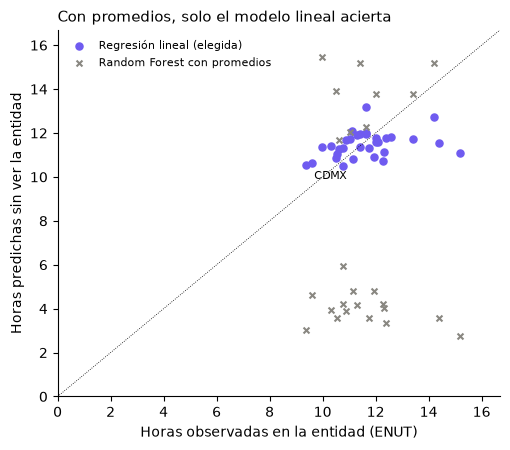

In [12]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(loso['observado'], loso['Regresión lineal'], color=MORADO, s=26, label='Regresión lineal (elegida)')
ax.scatter(loso['observado'], loso['Random Forest (promedios)'], color=GRIS, s=18, marker='x', label='Random Forest con promedios')
cd = loso[loso.cve_ent == '09']
ax.annotate('CDMX', (cd['observado'].iloc[0], cd['Regresión lineal'].iloc[0]), xytext=(6, -10), textcoords='offset points', fontsize=8)
lim = [0, max(loso[['observado', 'Regresión lineal']].max()) * 1.1]
ax.plot(lim, lim, color='k', lw=.6, ls=':'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Horas observadas en la entidad (ENUT)'); ax.set_ylabel('Horas predichas sin ver la entidad')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('Con promedios, solo el modelo lineal acierta', loc='left', fontsize=11)
plt.tight_layout(); fig.savefig(FIG / 'validacion_modelo_entidades.png', dpi=150, bbox_inches='tight'); plt.show()

---
## 4. Horas de cuidado no remunerado por AGEB (estimación en áreas pequeñas)

Se aplican los coeficientes a las variables del Censo 2020 de las **2,320 AGEB** del observatorio. Antes se **calibra con la CDMX**: el modelo, aplicado a los totales del Censo de la ciudad, debe dar el promedio que mide la ENUT para las mujeres de 15 a 59 de la CDMX. La diferencia se corrige con un factor único para todas las AGEB (*benchmarking*). Así las AGEB se ordenan según el modelo y su suma cuadra con la encuesta.

**Advertencias.** (1) Es una **estimación**, no una medición: hereda los errores del modelo (MAPE de ~8 % por entidad; en una AGEB será mayor). (2) Cuenta solo a las mujeres de 15 a 59. (3) Hereda las salvedades del hallazgo B: las ubicaciones de las AGEB son aproximadas.

In [13]:
censo = pd.read_csv(next(DIRS['censo_ageb_09'].rglob('conjunto_de_datos/*.csv')), encoding='utf-8-sig', dtype=str, low_memory=False)
VARS_C = ['P_0A2', 'P_3A5', 'P_6A11', 'P_12A14', 'P_60YMAS', 'PCDISC_MOT2', 'PROM_OCUP', 'P_15A17_F', 'P_18A24_F', 'P_15A49_F',
          'P_15YMAS_F', 'P_60YMAS_F', 'POCUPADA_F', 'P_12YMAS_F', 'GRAPROES_F', 'PHOGJEF_F', 'POBHOG', 'TOTHOG']

def variables_censo(df):
    d = df[VARS_C].apply(lambda s: pd.to_numeric(s.replace({'*': np.nan, 'N/D': np.nan}), errors='coerce'))
    m1559 = d['P_15YMAS_F'] - d['P_60YMAS_F']
    return pd.DataFrame({
        'n_0a5': (d.P_0A2 + d.P_3A5) / d.TOTHOG, 'n_6a14': (d.P_6A11 + d.P_12A14) / d.TOTHOG,
        'n_60mas': d.P_60YMAS / d.TOTHOG, 'n_disc': d.PCDISC_MOT2 / d.TOTHOG, 'tam': d.PROM_OCUP,
        'edad_15a24': (d.P_15A17_F + d.P_18A24_F) / m1559, 'edad_50a59': (m1559 - d.P_15A49_F) / m1559,
        'ocupada': d.POCUPADA_F / d.P_12YMAS_F, 'anios_esc': d.GRAPROES_F, 'jefa_hog': d.PHOGJEF_F / d.POBHOG,
        'urbana': 1.0, 'mujeres_15a59': m1559}, index=df.index)

ageb_c = censo[censo['NOM_LOC'] == 'Total AGEB urbana'].copy()
ageb_c['cvegeo_ageb'] = ageb_c['ENTIDAD'] + ageb_c['MUN'] + ageb_c['LOC'] + ageb_c['AGEB']
va = variables_censo(ageb_c).set_index(ageb_c['cvegeo_ageb'])
cdmx_c = variables_censo(censo[censo['NOM_LOC'] == 'Total de la entidad']).iloc[0]

pred_cdmx = float(final.predict(cdmx_c[X_COLS].to_numpy(float).reshape(1, -1))[0])
obs_cdmx = float(np.average(mujeres.loc[mujeres.cve_ent == '09', Y], weights=mujeres.loc[mujeres.cve_ent == '09', 'fac_per']))
FACTOR = obs_cdmx / pred_cdmx
print(f'CDMX: ENUT {obs_cdmx:.2f} h · modelo con el Censo {pred_cdmx:.2f} h · factor de calibración {FACTOR:.3f}')

base = pd.read_csv(CUR / 'mujeres_carga_acceso_ageb.csv', dtype={'CVEGEO_AGEB': str, 'MUN': str})
faltan = va.loc[base['CVEGEO_AGEB'], X_COLS].isna().any(axis=1)
print(f'AGEB del observatorio: {len(base):,} · con alguna variable reservada por confidencialidad: {int(faltan.sum())}')
# Si falta una variable (celda reservada), se usa la mediana de su alcaldía: no se inventa un cero.
vx = va.loc[base['CVEGEO_AGEB'], X_COLS].copy(); vx['MUN'] = base['MUN'].to_numpy()
vx[X_COLS] = vx.groupby('MUN')[X_COLS].transform(lambda s: s.fillna(s.median()))
horas_mujer = np.clip(final.predict(vx[X_COLS].to_numpy(float)) * FACTOR, 0, None)
horas = pd.DataFrame({'cvegeo_ageb': base['CVEGEO_AGEB'], 'cve_mun': base['MUN'], 'alcaldia': base['NOM_MUN'],
                      'mujeres_15a59': base['mujeres_15a59'].astype(int), 'horas_mujer_semana': horas_mujer,
                      'alta_carga': base['alta_carga'], 'sin_respaldo': base['sin_respaldo'],
                      'variables_imputadas': faltan.to_numpy()})
horas['horas_semana_total'] = np.floor(horas['horas_mujer_semana'] * horas['mujeres_15a59'] + 0.5).astype(int)
print(f"Horas estimadas por mujer: mín {horas.horas_mujer_semana.min():.1f} · mediana {horas.horas_mujer_semana.median():.1f} · máx {horas.horas_mujer_semana.max():.1f}")
print(f"Correlación con la carga directa x100 mujeres: {np.corrcoef(horas.horas_mujer_semana, base.carga_directa_x100_mujeres)[0, 1]:.2f}")

CDMX: ENUT 9.37 h · modelo con el Censo 10.99 h · factor de calibración 0.852
AGEB del observatorio: 2,320 · con alguna variable reservada por confidencialidad: 7
Horas estimadas por mujer: mín 7.0 · mediana 9.3 · máx 13.7
Correlación con la carga directa x100 mujeres: 0.58


In [14]:
SALARIO_HORA = 342.47 / 8          # salario mínimo profesional de las trabajadoras del hogar 2026, por hora
res_horas = pd.DataFrame({
    'AGEB': [len(horas), int(horas.alta_carga.sum()), int(horas.sin_respaldo.sum())],
    'Mujeres de 15 a 59': [horas.mujeres_15a59.sum(), horas.loc[horas.alta_carga, 'mujeres_15a59'].sum(), horas.loc[horas.sin_respaldo, 'mujeres_15a59'].sum()],
    'Horas por mujer a la semana': [np.average(horas.horas_mujer_semana, weights=horas.mujeres_15a59),
                                    np.average(horas.loc[horas.alta_carga, 'horas_mujer_semana'], weights=horas.loc[horas.alta_carga, 'mujeres_15a59']),
                                    np.average(horas.loc[horas.sin_respaldo, 'horas_mujer_semana'], weights=horas.loc[horas.sin_respaldo, 'mujeres_15a59'])],
    'Horas totales a la semana': [horas.horas_semana_total.sum(), horas.loc[horas.alta_carga, 'horas_semana_total'].sum(), horas.loc[horas.sin_respaldo, 'horas_semana_total'].sum()],
}, index=['Las 2,320 AGEB', 'Alta carga (580)', 'Alta carga y sin respaldo (88)'])
res_horas['Equivalente en jornadas de 40 h'] = res_horas['Horas totales a la semana'] / 40
res_horas['Valor semanal a salario mínimo del trabajo del hogar ($)'] = res_horas['Horas totales a la semana'] * SALARIO_HORA
por_alc_h = (horas.groupby('alcaldia').agg(horas_semana=('horas_semana_total', 'sum'), mujeres=('mujeres_15a59', 'sum'))
             .assign(horas_por_mujer=lambda d: d.horas_semana / d.mujeres).sort_values('horas_por_mujer', ascending=False))
display(res_horas.round(1)); por_alc_h.round(1)

,AGEB,Mujeres de 15 a 59,Horas por mujer a la semana,Horas totales a la semana,Equivalente en jornadas de 40 h,Valor semanal a salario mínimo del trabajo del hogar ($)
"Las 2,320 AGEB",2320,3102373,9.4,29184280,729607.0,1.249343e+09
Alta carga (580),580,875976,9.9,8671611,216790.3,3.712208e+08
Alta carga y sin respaldo (88),88,125256,10.2,1274554,31863.8,5.456206e+07


,horas_semana,mujeres,horas_por_mujer
alcaldia,,,
Cuajimalpa de Morelos,760415,75301,10.1
Milpa Alta,434377,43224,10.0
Tláhuac,1285198,132621,9.7
Benito Juárez,1486350,154104,9.6
Xochimilco,1386124,144342,9.6
Miguel Hidalgo,1364328,142590,9.6
Gustavo A. Madero,3662000,388340,9.4
Iztapalapa,5816155,618243,9.4
Tlalpan,2191880,233477,9.4


**Lectura.** En las AGEB de alta carga, una mujer de 15 a 59 cuida en promedio más horas que en el resto de la ciudad. En las **88 AGEB sin respaldo**, las mujeres hacen cada semana un volumen de cuidado no remunerado equivalente a varios miles de jornadas completas, sin ninguna guardería, residencia ni centro de día a 1 km. Es la demanda que el programa de la sección 5 puede atender en parte.

---
## 5. Factibilidad: ¿invertir en una red de cuidado a domicilio en Iztapalapa?

**Por qué este programa.** Sale de los hallazgos, no de una idea previa:

- *Hallazgo B y sección 4.* Iztapalapa concentra 25 de las 88 AGEB sin respaldo (40,199 mujeres) y ahí se cuidan muchas horas.
- *Secciones 1 y 2.* La oferta formal no va a cerrar esa brecha: cayó 37 % y el mejor pronóstico es que se quede igual.
- *Hallazgo C (ENASIC, nacional).* El 61.2 % de las cuidadoras preferiría el cuidado **en casa**, solo 3.9 % en un centro, y 44.4 % trabajaría como cuidadora si le pagaran.

**El programa.** Cuidado a domicilio por horas en esas 25 AGEB. Lo dan cuidadoras de las mismas colonias, capacitadas y verificadas, y la vinculación con las familias la hace la plataforma de *matching* del equipo. Opera el Centro Comunitario «Manos que Cuidan» (escenario simulado). Arranca con un piloto de 15 familias y 6 cuidadoras (incidente crítico del PP) y después se escala.

Todas las reglas del modelo financiero están en `backend/observatorio/factibilidad.py`, para que el notebook, el Excel y la app usen las mismas.

In [15]:
zona = base[(base.NOM_MUN == 'Iztapalapa') & base.sin_respaldo]
personas_nec = (zona['pob_0a5'] + zona['PCDISC_MOT2']).sum()
hh = sd.assign(nec=(sd.edad <= 5) | sd.disc).groupby('llavehog').agg(nec=('nec', 'sum'), fac=('fac_hog', 'first'))
con_nec = hh[hh.nec > 0]
factor_hogar = np.average(con_nec.nec, weights=con_nec.fac)
hogares_zona = int(round(personas_nec / factor_hogar))
print(f'AGEB de la zona: {len(zona)} · mujeres 15-59: {int(zona.mujeres_15a59.sum()):,} · hogares: {int(zona.TOTHOG.sum()):,}')
print(f'Personas con necesidad de cuidado directo: {int(personas_nec):,} · por hogar con necesidad (ENUT): {factor_hogar:.3f}')
print(f'Hogares con necesidad de cuidado en la zona: {hogares_zona:,}  (constante del módulo: {fac.HOGARES_ZONA:,})')
assert hogares_zona == fac.HOGARES_ZONA, 'actualizar HOGARES_ZONA en backend/observatorio/factibilidad.py'

AGEB de la zona: 25 · mujeres 15-59: 40,199 · hogares: 31,137
Personas con necesidad de cuidado directo: 11,359 · por hogar con necesidad (ENUT): 1.206
Hogares con necesidad de cuidado en la zona: 9,415  (constante del módulo: 9,415)


In [16]:
resultados = fac.evaluar_escenarios()
filas = []
for nombre, r in resultados.items():
    fila = {'Escenario': nombre, 'Probabilidad': fac.PROBABILIDADES[nombre]}
    for clave, _, fn in fac.INDICADORES:
        fila[clave] = fn(r)
    filas.append(fila)
comparativa = pd.DataFrame(filas).set_index('Escenario').T
ve_sin = fac.valor_esperado(resultados); ve_con = fac.valor_esperado(resultados, con_revision=True)
print(f'Valor esperado del VAN, operando pase lo que pase: ${ve_sin:,.0f}')
print(f'Valor esperado del VAN, con revisión en el mes 12:  ${ve_con:,.0f}')
comparativa

Valor esperado del VAN, operando pase lo que pase: $225,376
Valor esperado del VAN, con revisión en el mes 12:  $1,083,760


Escenario,Pesimista,Realista,Optimista
Probabilidad,3.000000e-01,0.500000,2.000000e-01
VAN,-4.031953e+06,487908.000264,5.955042e+06
VAN con revisión en el mes 12,-1.170673e+06,487908.000264,5.955042e+06
Se cierra en la revisión del mes 12,1.000000e+00,0.000000,0.000000e+00
TIR anual,NaN,31.525095,2.599289e+02
Payback,NaN,37.000000,1.500000e+01
Payback descontado,NaN,42.000000,1.500000e+01
Punto de equilibrio,1.769091e+04,4768.627451,5.721569e+03
Punto de equilibrio en familias,6.804196e+02,137.556561,1.320362e+02
Utilidad neta acumulada (60 meses),-5.078091e+06,912104.200000,8.054029e+06


In [17]:
supuestos_tabla = pd.DataFrame({n: {etq: getattr(s, campo) for campo, etq, _ in fac.VARIABLES_ESCENARIO} for n, s in fac.ESCENARIOS.items()})
display(supuestos_tabla)

# ¿Qué subsidio por hora hace VAN = 0 en el escenario realista? (bisección)
def van_con_subsidio(sub):
    return fac.evaluar(fac.con_cambios(fac.ESCENARIOS['Realista'], subsidio_hora=sub)).van
lo, hi = 0.0, 80.0
for _ in range(60):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if van_con_subsidio(mid) < 0 else (lo, mid)
SUBSIDIO_EQUILIBRIO = (lo + hi) / 2
print(f'Subsidio mínimo para VAN ≥ 0 en el escenario realista: ${SUBSIDIO_EQUILIBRIO:.2f} por hora')
sens = pd.DataFrame([{'tasa de descuento': t, 'VAN realista': fac.evaluar(fac.con_cambios(fac.ESCENARIOS['Realista'], tasa_descuento_anual=t)).van}
                     for t in (0.08, 0.10, 0.12, 0.15)])
sens2 = pd.DataFrame([{'subsidio por hora': s, 'VAN realista': van_con_subsidio(s),
                       'se cierra en el mes 12': fac.evaluar(fac.con_cambios(fac.ESCENARIOS['Realista'], subsidio_hora=s)).se_cierra_en_revision}
                      for s in (20, 30, 35, 40, 45, 50)])
display(sens.round({'VAN realista': 0})); sens2.round({'VAN realista': 0})

,Pesimista,Realista,Optimista
Adopción en estado estable,0.01,0.02,0.032
Horas contratadas por familia,6.00,8.00,10.000
Subsidio público por hora,20.00,40.00,40.000
Meses para llegar al estado estable,24.00,18.00,12.000


Subsidio mínimo para VAN ≥ 0 en el escenario realista: $38.01 por hora


,tasa de descuento,VAN realista
0,0.08,558421.0
1,0.10,487908.0
2,0.12,423134.0
3,0.15,335512.0


,subsidio por hora,VAN realista,se cierra en el mes 12
0,20,-4408320.0,True
1,30,-1960206.0,True
2,35,-736149.0,False
3,40,487908.0,False
4,45,1711965.0,False
5,50,2936022.0,False


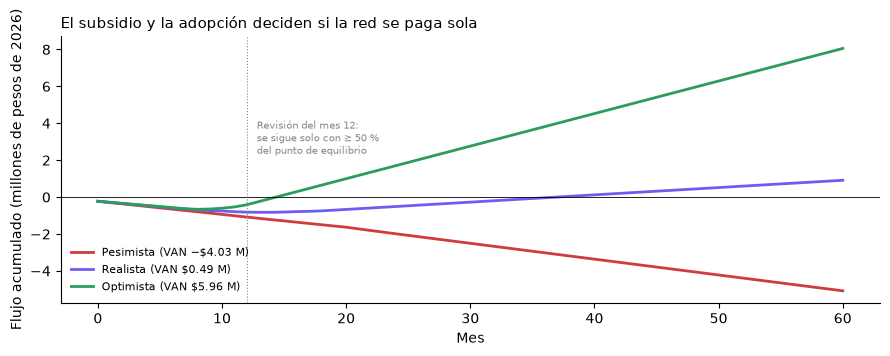

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colores = {'Pesimista': ROJO, 'Realista': MORADO, 'Optimista': '#2a9d5c'}
for nombre, r in resultados.items():
    acum = [m['flujo_acumulado'] for m in r.meses]
    ax.plot(range(len(acum)), np.array(acum) / 1e6, color=colores[nombre], lw=2, label=f"{nombre} (VAN {'−' if r.van < 0 else ''}${abs(r.van) / 1e6:,.2f} M)")
ax.axhline(0, color='k', lw=.6); ax.axvline(12, color=GRIS, lw=.8, ls=':')
ax.text(12.8, 4.2, 'Revisión del mes 12:\nse sigue solo con ≥ 50 %\ndel punto de equilibrio', fontsize=7.5, color=GRIS, va='top')
ax.set_xlabel('Mes'); ax.set_ylabel('Flujo acumulado (millones de pesos de 2026)')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('El subsidio y la adopción deciden si la red se paga sola', loc='left', fontsize=11)
plt.tight_layout(); fig.savefig(FIG / 'escenarios_flujo_acumulado.png', dpi=150, bbox_inches='tight'); plt.show()

**Decisión según los escenarios.** El VAN esperado es positivo, pero el pesimista pierde mucho si se opera "pase lo que pase". El riesgo no es simétrico, así que la recomendación es **invertir por etapas, condicionado a tres cosas**:

1. **Convenio de subsidio** con el Sistema Público de Cuidados de al menos **$40 por hora** (el VAN realista llega a cero alrededor de $38).
2. **Revisión en el mes 12.** Se sigue solo con al menos 50 % de las familias del punto de equilibrio (≈ 69 de 138). Con esa regla, el escenario pesimista se cierra a tiempo y su pérdida baja de ~$4.0 M a ~$1.2 M.
3. **Financiamiento comprometido** por el déficit acumulado máximo del escenario realista (~$0.82 M) más 10 %. La fórmula clásica (inversión + 3 meses de operación + 10 %) da ~$0.62 M y **subestima** lo que el programa necesita antes de alcanzar el equilibrio.

---
## 6. Exportación a `data/curada/` y anexo de Excel

Mismas reglas que el notebook 02: cada CSV lleva `nivel_geografico` y `fuente`. El ETL (`etl/cargar_capas.py`) los carga sin recalcular nada en seis tablas nuevas de `indicadores` (ver `docs/diccionario_datos.md`).

In [19]:
FTE_DENUE_H = 'INEGI, DENUE (19 ediciones, 01/2016 a 05/2026)'
FTE_MODELO = 'Modelo PP7 con INEGI, ENUT 2024'
FTE_AGEB = 'Modelo PP7 con INEGI, ENUT 2024 + Censo 2020'
FTE_PROGRAMA = 'Escenario simulado PP7 (backend/observatorio/factibilidad.py)'

def exportar(df, archivo, nivel, fuente):
    out = df.copy(); out['nivel_geografico'] = nivel; out['fuente'] = fuente
    out.to_csv(CUR / archivo, index=False)
    print(f'{archivo:40} {len(out):>5} filas x {out.shape[1]:>2} columnas')
    return out

exportar(oferta[['edicion', 'periodo', 'tipo', 'sector', 'establecimientos']].sort_values(['edicion', 'tipo', 'sector']),
         'denue_oferta_historica.csv', 'CDMX', FTE_DENUE_H)
exportar(pronostico, 'pronostico_oferta_cdmx.csv', 'CDMX', FTE_DENUE_H)

val = []
for _, f in bt.iterrows():
    for met in ('MAPE', 'RMSE', 'MAE'):
        val.append({'modelo': f.modelo, 'tarea': f'Pronóstico de la oferta de respaldo, h = {f.h} semestre(s)',
                    'conjunto': 'Origen móvil', 'metrica': met, 'valor': f[met], 'n_evaluaciones': int(f.n),
                    'elegido': f.modelo == 'Ingenuo', 'nivel_geografico': 'CDMX', 'fuente': FTE_DENUE_H})
for f in res_ind:
    for met in ('RMSE', 'MAE', 'R2'):
        if pd.notna(f.get(met)):
            val.append({'modelo': f['modelo'], 'tarea': 'Horas de cuidado por mujer (individual)', 'conjunto': f['conjunto'],
                        'metrica': met, 'valor': f[met], 'n_evaluaciones': len(prueba) if f['conjunto'].startswith('Prueba') else 5,
                        'elegido': f['modelo'] == 'Regresión lineal', 'nivel_geografico': 'Nacional', 'fuente': FTE_MODELO})
for _, f in res_eco.iterrows():
    for met in ('MAPE', 'RMSE', 'MAE', 'R2'):
        val.append({'modelo': f.modelo, 'tarea': 'Horas de cuidado promedio de una entidad (aplicación con el Censo)',
                    'conjunto': 'Dejando fuera una entidad (32)', 'metrica': met, 'valor': f[met], 'n_evaluaciones': 32,
                    'elegido': f.modelo == 'Regresión lineal', 'nivel_geografico': 'Nacional', 'fuente': FTE_MODELO})
validacion = pd.DataFrame(val)
# Aquí el nivel y la fuente cambian por fila (pronóstico: CDMX; modelo: nacional o por entidad).
validacion.to_csv(CUR / 'validacion_modelos.csv', index=False)
print(f'{"validacion_modelos.csv":40} {len(validacion):>5} filas x {validacion.shape[1]:>2} columnas')
exportar(coef, 'modelo_horas_coeficientes.csv', 'Nacional', FTE_MODELO)
exportar(horas[['cvegeo_ageb', 'cve_mun', 'alcaldia', 'mujeres_15a59', 'horas_mujer_semana', 'horas_semana_total',
                'alta_carga', 'sin_respaldo', 'variables_imputadas']], 'horas_cuidado_ageb.csv', 'AGEB', FTE_AGEB)

esc = []
for nombre, r in resultados.items():
    esc.append({'escenario': nombre, 'indicador': 'Probabilidad asignada', 'valor': fac.PROBABILIDADES[nombre] * 100, 'unidad': '%'})
    for campo, etq, unidad in fac.VARIABLES_ESCENARIO:
        v = getattr(r.supuestos, campo)
        esc.append({'escenario': nombre, 'indicador': f'Supuesto: {etq}', 'valor': v * 100 if campo == 'adopcion' else v,
                    'unidad': '%' if campo == 'adopcion' else unidad})
    for clave, unidad, fn in fac.INDICADORES:
        esc.append({'escenario': nombre, 'indicador': clave, 'valor': fn(r), 'unidad': unidad})
esc += [{'escenario': 'Valor esperado', 'indicador': 'VAN', 'valor': ve_sin, 'unidad': 'pesos'},
        {'escenario': 'Valor esperado', 'indicador': 'VAN con revisión en el mes 12', 'valor': ve_con, 'unidad': 'pesos'},
        {'escenario': 'Zona del programa', 'indicador': 'Hogares con necesidad de cuidado', 'valor': hogares_zona, 'unidad': 'hogares'},
        {'escenario': 'Zona del programa', 'indicador': 'Subsidio mínimo para VAN ≥ 0 (realista)', 'valor': SUBSIDIO_EQUILIBRIO, 'unidad': 'pesos por hora'},
        {'escenario': 'Zona del programa', 'indicador': 'Tasa de descuento (real anual)', 'valor': fac.ESCENARIOS['Realista'].tasa_descuento_anual * 100, 'unidad': '%'}]
escenarios = exportar(pd.DataFrame(esc), 'escenarios_programa.csv', 'AGEB', FTE_PROGRAMA)

denue_oferta_historica.csv                 114 filas x  7 columnas
pronostico_oferta_cdmx.csv                  60 filas x 12 columnas
validacion_modelos.csv                      56 filas x  9 columnas
modelo_horas_coeficientes.csv               12 filas x  6 columnas
horas_cuidado_ageb.csv                    2320 filas x 11 columnas
escenarios_programa.csv                     74 filas x  6 columnas


In [20]:
import anexo_excel
ruta = anexo_excel.construir(ANEXOS / 'anexo_A_calculos_pp7.xlsx', resultados=resultados, oferta=tabla, semestral=semestral,
                             backtest=bt, pronostico=pronostico, coeficientes=coef, validacion=validacion,
                             hogares_zona=hogares_zona, subsidio_equilibrio=SUBSIDIO_EQUILIBRIO,
                             ejemplo=cdmx_c[X_COLS].to_dict(), factor=FACTOR)
print('Anexo de Excel:', ruta.relative_to(BASE))

Anexo de Excel: docs/anexos/anexo_A_calculos_pp7.xlsx


---
## 7. Resumen de cifras para el reporte

Solo cifras, para citarlas sin volver a correr todo. La interpretación está en el reporte ejecutivo del equipo.

In [21]:
real = resultados['Realista']
resumen = pd.Series({
    'DENUE · respaldo 01/2016': int(total.loc['2016-01']), 'DENUE · respaldo 05/2026': int(total.loc['2026-05']),
    'DENUE · cambio 2016-2026 (%)': round(cambio, 1),
    'Pronóstico · 2026-S2 (ingenuo)': float(ing.pronostico.iloc[0]),
    'Pronóstico · 2026-S2 IC80': f'{ing.li_80.iloc[0]:.0f}–{ing.ls_80.iloc[0]:.0f}',
    'Pronóstico · 2027-S2 IC80': f'{ing.li_80.iloc[2]:.0f}–{ing.ls_80.iloc[2]:.0f}',
    'Pronóstico · MAPE h=1 (ingenuo)': round(bt[(bt.h == 1) & (bt.modelo == 'Ingenuo')].MAPE.iloc[0], 2),
    'Modelo · R2 prueba lineal': round(res_ind[0]['R2'], 3),
    'Modelo · MAPE entidades lineal': round(res_eco.MAPE.iloc[0], 2),
    'Modelo · MAPE entidades RF promedios': round(res_eco.MAPE.iloc[1], 2),
    'AGEB · horas/semana en las 88 sin respaldo': round(res_horas.loc['Alta carga y sin respaldo (88)', 'Horas totales a la semana']),
    'Programa · VAN realista': round(real.van), 'Programa · TIR realista (%)': round(real.tir_anual * 100, 1),
    'Programa · VAN esperado con revisión': round(ve_con), 'Programa · subsidio de equilibrio ($/h)': round(SUBSIDIO_EQUILIBRIO, 2),
})
resumen.to_frame('valor')

,valor
DENUE · respaldo 01/2016,1337
DENUE · respaldo 05/2026,838
DENUE · cambio 2016-2026 (%),-37.3
Pronóstico · 2026-S2 (ingenuo),838.0
Pronóstico · 2026-S2 IC80,677–847
Pronóstico · 2027-S2 IC80,596–847
Pronóstico · MAPE h=1 (ingenuo),2.92
Modelo · R2 prueba lineal,0.311
Modelo · MAPE entidades lineal,7.8
Modelo · MAPE entidades RF promedios,50.57
